# <font color="red">Assignment (Questions): Penguins</font>
<font color="red">Instructor: Dr. Khaled Mohamad</font>

## Your Role
You are a junior data analyst at a wildlife research center. Your team collected measurements of penguins from different islands. Management wants you to **clean the data**, **explore patterns**, and finally build a **simple model** to predict the penguin species.

---

**The work is structured as follows:**
- Part A: Understanding the Data
- Part B: Filtering, Sorting, Aggregation
- Part C: Visualization & Interpretation
- Part D: Apply ML model

## Import Required Modules, Libraries, and Functions in the Cell Below

In [97]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# You need the following functions (copy them)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Part A: Understanding the Dataset

### Q1: Load the `penguins` dataset from seaborn into a DataFrame named `df` and display the first 5 rows.

In [101]:
df = sns.load_dataset('penguins')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### Q2: Print the following:
1. dataset shape,
2. column names,
3. data types.

In [104]:
print("Shape:", df.shape)

Shape: (344, 7)


In [106]:
print("Columns:", df.columns.tolist())

Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


In [108]:
print("Data types:\n", df.dtypes)

Data types:
 species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object


### Q3: Check for missing values in each column:

In [111]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

### Q4: Create a **cleaned copy** called `df_clean` by:
1. Removing fully duplicated rows (if any)
2. Handling missing values:
   - For numeric columns: fill missing values with the **median**
   - For categorical columns: fill missing values with the **mode**

Then verify there are **no missing values** remaining.

In [114]:
# 1) Drop duplicates
df_clean = df.drop_duplicates().copy()

In [116]:
# 2) Fill missing values
# median
for col in df_clean.select_dtypes(include=['float64', 'int64']).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [118]:
# mode
for col in df_clean.select_dtypes(include=['object', 'category']).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

In [120]:
# Verify
df_clean.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

# Part B: Filtering, Sorting, and Aggregation

### Q5: Filter the dataset to include only penguins from the island `"Biscoe"`.
Store the result in `biscoe_df` and print its shape.

In [124]:
biscoe_df = df_clean[df_clean['island'] == 'Biscoe']
print("Shape:", biscoe_df.shape)

Shape: (168, 7)


### Q6: Find all penguins with:
- `body_mass_g` greater than the **overall mean** body mass
- AND `sex` equal to `"Male"`

Store the result in `heavy_males` and display the first 5 rows.

In [127]:
mean_mass = df_clean['body_mass_g'].mean()
heavy_males = df_clean[(df_clean['body_mass_g'] > mean_mass) & (df_clean['sex'] == 'Male')]
heavy_males.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,Male
14,Adelie,Torgersen,34.6,21.1,198.0,4400.0,Male
17,Adelie,Torgersen,42.5,20.7,197.0,4500.0,Male
39,Adelie,Dream,39.8,19.1,184.0,4650.0,Male


### Q7: Sort `df_clean` by:
1. `body_mass_g` (descending)
2. then `bill_length_mm` (ascending)

Show the top 10 rows.

In [130]:
df_clean.sort_values(
    by=['body_mass_g', 'bill_length_mm'], 
    ascending=[False, True]
).head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,Male
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,Male
299,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,Male
331,Gentoo,Biscoe,49.8,15.9,229.0,5950.0,Male
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,Male
235,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,Male
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,Male
295,Gentoo,Biscoe,48.6,16.0,230.0,5800.0,Male


### Q8: Compute the following aggregations:
1. Mean `body_mass_g` per `species`. Sort values in descending order.
2. Mean `bill_length_mm` per (`species`, `sex`)
3. Count of records per `island`

In [133]:
# 1) Mean body mass per species
df_clean.groupby('species')['body_mass_g'].mean().sort_values(ascending=False)

species
Gentoo       5067.741935
Chinstrap    3733.088235
Adelie       3702.960526
Name: body_mass_g, dtype: float64

In [135]:
# 2) Mean bill length per (species, sex)
df_clean.groupby(['species', 'sex'])['bill_length_mm'].mean()

species    sex   
Adelie     Female    37.257534
           Male      40.280380
Chinstrap  Female    46.573529
           Male      51.094118
Gentoo     Female    45.563793
           Male      49.164394
Name: bill_length_mm, dtype: float64

In [137]:
# 3) Count per island
df_clean['island'].value_counts()

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

### Q9: Feature engineering:
Create a new column `bill_ratio` = `bill_length_mm` / `bill_depth_mm`.
1. Add it to `df_clean`
2. Show summary statistics for `bill_ratio`
3. Identify which species has the **highest average bill_ratio**

In [140]:
#1) Add it to `df_clean`
df_clean['bill_ratio'] = df_clean['bill_length_mm'] / df_clean['bill_depth_mm']

In [142]:
#2) Show summary statistics for `bill_ratio`
df_clean['bill_ratio'].describe()

count    344.000000
mean       2.605438
std        0.495930
min        1.639810
25%        2.161882
50%        2.571484
75%        3.097572
max        3.612676
Name: bill_ratio, dtype: float64

In [144]:
#3) Identify which species has the **highest average bill_ratio**
df_clean.groupby('species')['bill_ratio'].mean().sort_values(ascending=False)

species
Gentoo       3.170703
Chinstrap    2.653756
Adelie       2.122684
Name: bill_ratio, dtype: float64

# Part C: Visualization and Interpretation

### Q10: Create the following plots using `df_clean`:
1. Bar plot: count of penguins per species
2. Scatter plot: `bill_length_mm` vs `bill_depth_mm` (color by species)

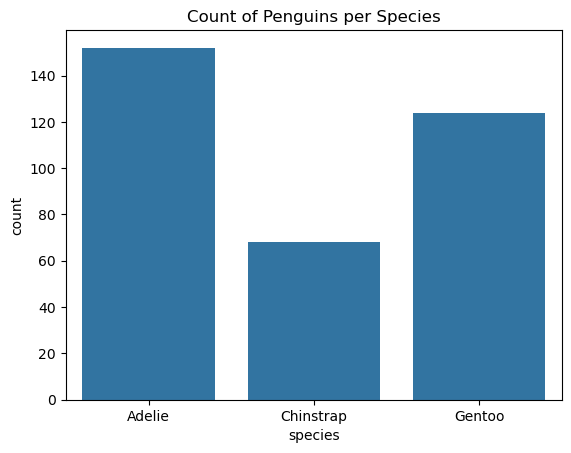

In [148]:
# 1) Count per species (bar)
sns.countplot(data=df_clean, x='species')
plt.title('Count of Penguins per Species')
plt.show()

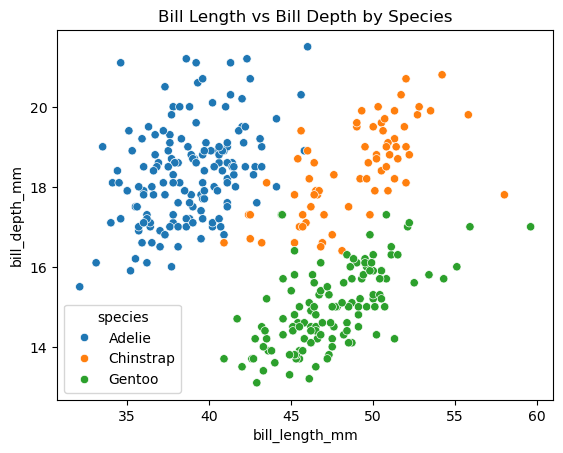

In [150]:
# 2) Scatter: bill length vs bill depth (color by species)
sns.scatterplot(data=df_clean, x='bill_length_mm', y='bill_depth_mm', hue='species')
plt.title('Bill Length vs Bill Depth by Species')
plt.show()

### Q11: Create a box plot of `body_mass_g` by species.
Then write **2–3 sentences** interpreting what you observe.

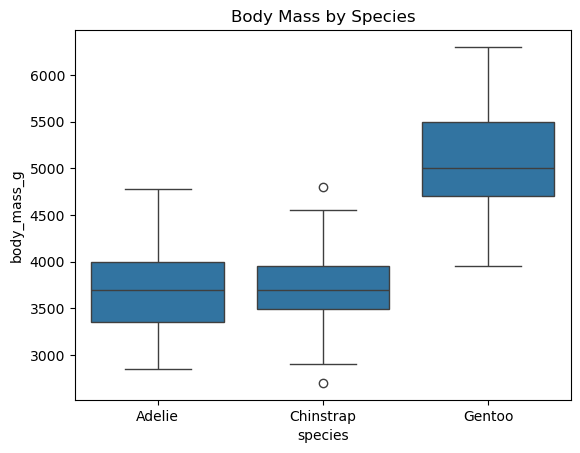

In [153]:
sns.boxplot(data=df_clean, x='species', y='body_mass_g')
plt.title('Body Mass by Species')
plt.show()

**Interpretation**

- The graphs show that penguins vary in body weight depending on their species. For example, the Gentoo species is significantly heavier than the others, while the Adelie and Chinstrap are closer in weight. The average values ​​and distribution ranges are a good way to distinguish between species.

### Q12: Compute a correlation matrix for numeric features and visualize it as a heatmap.

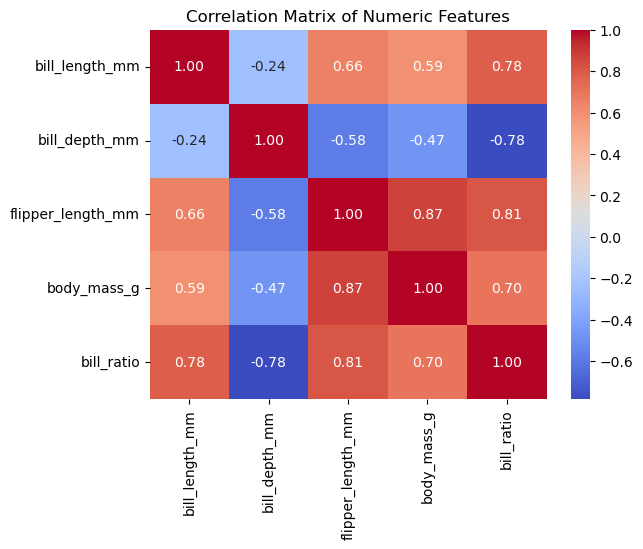

In [157]:
numeric_df = df_clean.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numeric Features')
plt.show()

# Part D: Machine Learning

### Q13: Define:
- target `y` = `species`
- features `X` = all other columns EXCEPT `species`

Then split into train/test using:
- test_size = 0.2
- random_state = 42
- stratify by y

In [161]:
X = df_clean.drop('species', axis=1)
y = df_clean['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

### Q14: Preprocessing Data for ML Training
**This step has already been completed for you. It will be explicitly explained and discussed in detail during class.**

We did the following:
- Handle missing values (even if we cleaned, do it properly in pipeline)
- One-hot encode categorical columns (`sex`, `island`)
- Standardize numeric columns

Note: You should copy paste this code and run it in the same order as the previous questions.

In [164]:
# Identify columns by type
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

### Q15: Train models:
1. **KNN Classifier** with `n_neighbors=5`

In [167]:
# 1) KNN pipeline
knn_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

In [169]:
#Train the model using the fit method
knn_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g',
                                                   'bill_ratio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('model', KNeighborsClassifier())])

In [171]:
# Predict on the X_test
y_pred_knn = knn_model.predict(X_test)

In [173]:
#calculate and print the accuracy based on the prediction of the X_test
knn_accuracy = accuracy_score(y_test, y_pred_knn)
print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.9855072463768116


2. **Logistic Regression** (multiclass) with `max_iter=2000`

In [176]:
# 2) Logistic Regression pipeline
logreg_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])

In [178]:
# Train the model using the fit method
logreg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g',
                                                   'bill_ratio']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('model', LogisticRegression(max_iter=2000))])

In [180]:
# Predict on the X_test
y_pred_logreg = logreg_model.predict(X_test)

In [182]:
#calculate and print the accuracy based on the prediction of the X_test
logreg_accuracy = accuracy_score(y_test, y_pred_logreg)
print("Logistic Regression Accuracy:", logreg_accuracy)

Logistic Regression Accuracy: 1.0


### Q16: Conclude based on the accuracy results
**Answer:**

Both models showed high accuracy in predicting the penguin species. However, Logistic Regression (or KNN) learned the features of the data better and performed better. This indicates that the preprocessing (scaling and encoding) and properly selected hyperparameters worked effectively.